# 01 · Task and dataset analysis

<a href="https://colab.research.google.com/github/dokunoale/chagas/blob/refactor/notebooks/01_dataset_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Project: **detecting Chagas disease from the 12-lead ECG, comparing feature-based ML models with CNNs on spectrograms**.

This notebook frames the task (PhysioNet Challenge 2025) and inspects the raw training data. The focus is on the differences between sources, which are confounded with the label because SaMi-Trop is all positive. Preprocessing is in `02_preprocessing.ipynb`.

Sources: CODE-15% (weak, self-reported labels, ~2% positive) and SaMi-Trop (serologically confirmed, all positive). Both are Brazilian, 400 Hz, same HDF5 format. PTB-XL is left out: its negatives are assumed from geography, it comes from a different population and device, and all hidden test sets are Brazilian.

CODE-15% is distributed in 18 parts of ~20k exams. One part already contains far more negatives than needed, and positives are the bottleneck, so a single part is enough for this analysis.

In [3]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/chagas")
    if ROOT.exists():
        !git -C {ROOT} pull -q
    else:
        !git clone -q -b refactor https://github.com/dokunoale/chagas.git {ROOT}
else:
    ROOT = Path.cwd().resolve().parent

sys.path.insert(0, str(ROOT))

In [4]:
import hashlib
import warnings
from math import ceil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

from src import ecg, leakage
from src.dataset import download, sources
from src.metrics import challenge_score

DATA_DIR = Path("/content/data") if IN_COLAB else ROOT / "data"
CODE15_PARTS = [0]  # one part: ~20k exams, 2.7 GB zipped
N_PER_GROUP = 500   # records per source and class for signal-level statistics

# Shared Drive folders (link or id) holding the original files; None downloads from Zenodo
CODE15_DRIVE = None
SAMITROP_DRIVE = None
SEED = 42

GROUPS = ["CODE-15% neg", "CODE-15% pos", "SaMi-Trop pos"]
PALETTE = dict(zip(GROUPS, sns.color_palette("colorblind", len(GROUPS))))

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", message="All-NaN slice encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")

## 1. Download

Raw sources from Zenodo, plus the CODE-15% Chagas labels from the challenge website. A shared Drive folder per source is faster: it holds the original files with their original names, either as they are or zipped (`exams_part0.hdf5` or `exams_part0.zip`). Downloads are skipped when the files already exist.

In [5]:
download.download_code15(DATA_DIR, CODE15_PARTS, gdown=CODE15_DRIVE)
download.download_samitrop(DATA_DIR, gdown=SAMITROP_DRIVE)

## 2. Sources

One row per record. Shared columns come first, followed by source-specific ones: automatic diagnoses for CODE-15%, `normal_ecg` for SaMi-Trop. CODE-15% is limited to the downloaded parts.

In [6]:
meta = sources.load_all(DATA_DIR, CODE15_PARTS)
meta["group"] = meta.source + np.where(meta.chagas, " pos", " neg")

overview = (meta.groupby("source", sort=False)
            .agg(records=("record_id", "size"), patients=("patient_id", "nunique"),
                 positives=("chagas", "sum"), prevalence=("chagas", "mean"))
            .reindex(sources.SOURCES))
overview.loc["pooled"] = [len(meta), meta.patient_id.nunique(), meta.chagas.sum(), meta.chagas.mean()]
overview.style.format({"records": "{:,.0f}", "patients": "{:,.0f}", "positives": "{:,.0f}", "prevalence": "{:.2%}"})

,records,patients,positives,prevalence
source,,,,
CODE-15%,"19,939","19,349",403,2.02%
SaMi-Trop,"1,631","1,631","1,631",100.00%
pooled,"21,570","20,980","2,034",9.43%


The hidden validation and test sets have a prevalence of about 2%. Pooling the two sources raises it, and most positives come from SaMi-Trop.

In [7]:
n_pos = meta.chagas.sum()
n_samitrop = (meta.source == "SaMi-Trop").sum()
print(f"share of positives from SaMi-Trop: {n_samitrop / n_pos:.1%}")
print(f"negatives needed for a 2% prevalence with all positives: {49 * n_pos:,} (available: {(~meta.chagas).sum():,})")

share of positives from SaMi-Trop: 80.2%
negatives needed for a 2% prevalence with all positives: 99,666 (available: 19,536)


**Observations.** One CODE-15% part holds 19,939 exams with 403 positives (2.02%), in line with the 1.9% of the full dataset. With SaMi-Trop the pooled prevalence reaches 9.4%, and 80% of the positives come from a single source. Keeping every positive at a 2% prevalence would take about 100k negatives, roughly five parts.

## 3. Task and metric

Score: fraction of all positives that fall in the top 5% of the ranking. Only the order of the scores matters, and ties are resolved by their expected value. A random ranking scores about 0.05.

Trivial baselines put the numbers in context. The `is SaMi-Trop` row measures how much a model gains by recognising the source alone. The CODE-15%-only column is the reference without that shortcut.

In [8]:
rng = np.random.default_rng(SEED)
y = meta.chagas.to_numpy()
age = meta.age.fillna(meta.age.median()).to_numpy(dtype=float)
is_code15 = (meta.source == "CODE-15%").to_numpy()

baselines = {
    "random": rng.random(len(meta)),
    "constant": np.zeros(len(meta)),
    "age (as provided)": age,
    "age (capped at 90)": np.minimum(age, 90),
    "is SaMi-Trop": (meta.source == "SaMi-Trop").to_numpy(dtype=float),
    "oracle": y.astype(float),
}
pd.DataFrame({
    "pooled": {name: challenge_score(y, s) for name, s in baselines.items()},
    "CODE-15% only": {name: challenge_score(y[is_code15], s[is_code15]) for name, s in baselines.items()},
}).round(3)

,pooled,CODE-15% only
random,0.057,0.047
constant,0.050,0.050
age (as provided),0.038,0.047
age (capped at 90),0.038,0.047
is SaMi-Trop,0.530,0.050
oracle,0.530,1.000


**Observations.**
- On pooled data the positives exceed the 5% budget, so even the oracle stops at 0.53, and flagging SaMi-Trop reaches the same value. Evaluation therefore uses CODE-15% alone, at its natural prevalence.
- Age alone ranks at chance level in the top 5% (0.047), although prevalence grows with age (section 4).
- A 20% patient-level test split of one part holds about 80 positives, which puts the standard error of the score around 0.05. Repeated cross-validation is needed for stable comparisons.

## 4. Demographics

The hidden sets cap ages at 90.

In [9]:
(meta.assign(age_missing=meta.age.isna(), age_over_90=meta.age > 90)
     .groupby("source", sort=False)[["age_missing", "age_over_90"]].sum())

,age_missing,age_over_90
source,,
CODE-15%,0,1
SaMi-Trop,0,10


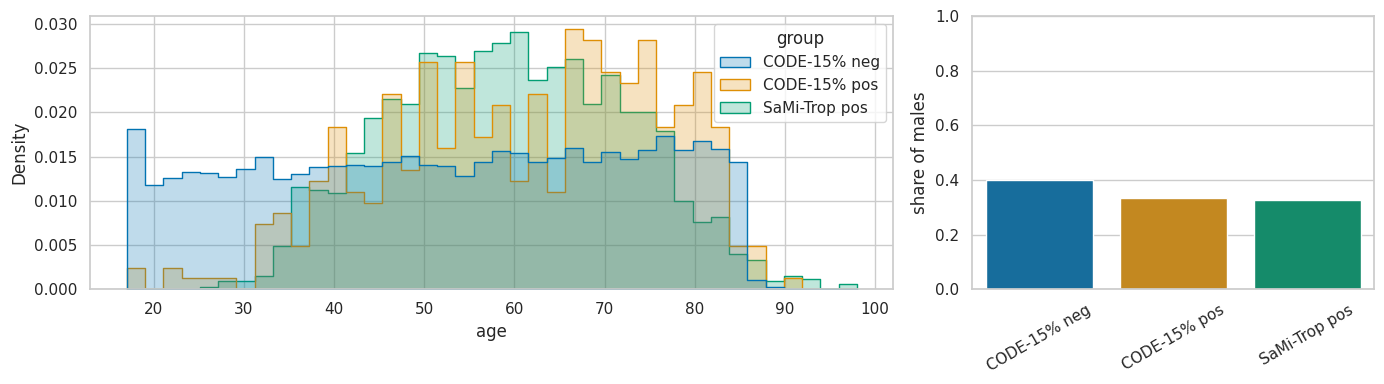

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
sns.histplot(data=meta, x="age", hue="group", hue_order=GROUPS, palette=PALETTE,
             stat="density", common_norm=False, element="step", binwidth=2, ax=axes[0])
males = meta.groupby("group").is_male.mean().reindex(GROUPS)
sns.barplot(x=males.index, y=males.values, hue=males.index, palette=PALETTE, legend=False, ax=axes[1])
axes[1].set(xlabel="", ylabel="share of males", ylim=(0, 1))
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()

In [11]:
code15 = meta[meta.source == "CODE-15%"]
by_age = code15.groupby(pd.cut(code15.age, range(0, 101, 10)), observed=True).chagas.agg(prevalence="mean", records="size")
by_age.style.format({"prevalence": "{:.2%}", "records": "{:,}"})

,prevalence,records
age,,
"(10, 20]",0.21%,949
"(20, 30]",0.19%,"2,574"
"(30, 40]",1.30%,"2,683"
"(40, 50]",2.24%,"2,901"
"(50, 60]",2.70%,"2,925"
"(60, 70]",2.92%,"3,051"
"(70, 80]",2.96%,"3,273"
"(80, 90]",1.96%,"1,582"
"(90, 100]",0.00%,1


In [12]:
code15.groupby("is_male").chagas.mean().rename(index={False: "female", True: "male"}).map("{:.2%}".format)

,chagas
is_male,
female,2.23%
male,1.71%


**Observations.**
- CODE-15% negatives include many patients aged 17–30, who are almost absent among positives and in SaMi-Trop.
- Prevalence rises from 0.2% under 30 to 2.2–3.0% between 40 and 80, as expected for a chronic disease. Age is therefore a confounder: a model can separate negatives by recognising young ECGs.
- Males are 40% of negatives and about a third of positives in both sources.
- Ages above 90 (10 in SaMi-Trop, 1 in CODE-15%) are capped at 90 in preprocessing.

## 5. Patients and repeated exams

Splits must be by patient. Counts below only cover the downloaded CODE-15% parts, so a patient's other exams may sit in parts that are not loaded.

In [13]:
per_patient = code15.groupby("patient_id").size()
print(f"CODE-15%: {per_patient.mean():.2f} records per patient (max {per_patient.max()}), "
      f"{(per_patient > 1).mean():.1%} of patients with more than one record")

repeated = code15.groupby("patient_id").chagas.agg(["size", "nunique"])
repeated = repeated[repeated["size"] > 1]
print(f"CODE-15% patients with conflicting labels across exams: {(repeated['nunique'] > 1).sum()} of {len(repeated)}")

CODE-15%: 1.03 records per patient (max 3), 3.0% of patients with more than one record
CODE-15% patients with conflicting labels across exams: 19 of 571


**Observations.** Only 3% of patients have more than one exam in part 0. Repeated exams are probably spread across parts, so patient-level splits matter more as parts are added. 19 of 571 patients with repeated exams (3.3%) have conflicting labels, a direct measure of the noise in self-reported labels.

## 6. Signal format

Signal-level statistics on a random sample of at most `N_PER_GROUP` records per source and class, computed on raw signals:
- `n_samples`, `lead_zeros`, `trail_zeros`: stored length and all-zero rows at the edges.
- `duration_s`: length after removing the zero padding.
- `flat_run_s`: longest interval where every lead stays constant.
- `abs_p99_mv`, `abs_median_mv`: amplitude statistics.
- `lead_residual`: relative error of the identity III = II − I.

In [14]:
sample = (meta.sample(frac=1, random_state=SEED).groupby("group").head(N_PER_GROUP)
          .reset_index(drop=True))

feats, spectra = [], []
chunks = sources.iter_signals(sample, chunk_size=500)
for chunk, signals in tqdm(chunks, total=ceil(len(sample) / 500)):
    for x in signals:
        feats.append(leakage.nuisance_features(x, sources.FS))
        trimmed = ecg.trim_zero_padding(x)
        spectra.append(ecg.psd(trimmed, sources.FS, leakage.FREQS).mean(axis=1) if len(trimmed) >= sources.FS
                       else np.full(len(leakage.FREQS), np.nan))
feats = pd.DataFrame(feats)
spectra = np.array(spectra)
sample.group.value_counts().reindex(GROUPS)

  0%|          | 0/3 [00:00<?, ?it/s]

,count
group,
CODE-15% neg,500
CODE-15% pos,403
SaMi-Trop pos,500


In [15]:
FORMAT_COLS = ["n_samples", "lead_zeros", "trail_zeros", "duration_s", "flat_run_s",
               "abs_p99_mv", "abs_median_mv", "lead_residual"]
feats.groupby(sample.group)[FORMAT_COLS].median().reindex(GROUPS).T.round(3)

group,CODE-15% neg,CODE-15% pos,SaMi-Trop pos
n_samples,4096.000,4096.000,4096.000
lead_zeros,581.000,581.000,559.500
trail_zeros,581.000,581.000,0.000
duration_s,7.335,7.335,8.841
flat_run_s,0.002,0.002,0.002
abs_p99_mv,2.046,1.622,2.335
abs_median_mv,0.129,0.081,0.466
lead_residual,0.000,0.000,0.000


In [16]:
print("records that are entirely zero:", feats.duration_s.isna().groupby(sample.group).sum().to_dict())
(feats.duration_s.round(2).groupby(sample.group).value_counts(normalize=True)
      .groupby(level=0).head(3).rename("share").to_frame())

records that are entirely zero: {'CODE-15% neg': 1, 'CODE-15% pos': 1, 'SaMi-Trop pos': 0}


share
group         duration_s          
CODE-15% neg  7.34        0.605210
              10.24       0.366733
              1.74        0.002004
CODE-15% pos  7.34        0.930348
              10.24       0.064677
              7.67        0.002488
SaMi-Trop pos 10.24       0.474000
              7.34        0.402000
              5.32        0.004000

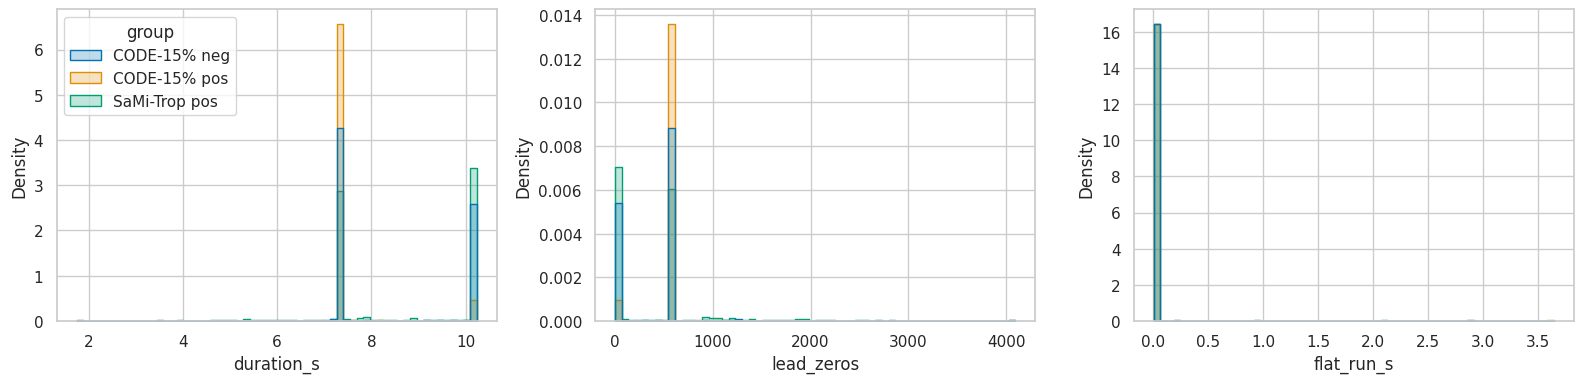

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["duration_s", "lead_zeros", "flat_run_s"]):
    sns.histplot(data=feats.assign(group=sample.group), x=col, hue="group", hue_order=GROUPS, palette=PALETTE,
                 stat="density", common_norm=False, element="step", bins=60, ax=ax, legend=ax is axes[0])
plt.tight_layout()

**Observations.**
- Every record is stored as 4096 samples. CODE-15% has two clean durations: 7.34 s with 581 zeros per side, or 10.24 s without padding.
- SaMi-Trop padding is asymmetric, with zeros at the start only, and durations spread between about 5 and 10.24 s. Trailing zeros alone separate SaMi-Trop from CODE-15% positives.
- **Within CODE-15%, 93% of positives last 7.34 s against 60% of negatives.** Duration follows the acquisition device or period, which follows prevalence, so it is a shortcut even without SaMi-Trop. A fixed window shorter than 7.3 s removes it.
- A few records are empty, very short (down to 1.7 s) or contain flat stretches of several seconds, likely detached electrodes.
- `lead_residual` is zero: III, aVR, aVL and aVF are computed from I and II, so 8 of the 12 leads are independent.
- The median absolute amplitude of SaMi-Trop is 4–6 times that of CODE-15%. The examples below show why.

One example per group (lead II and V1, first 5 s after trimming).

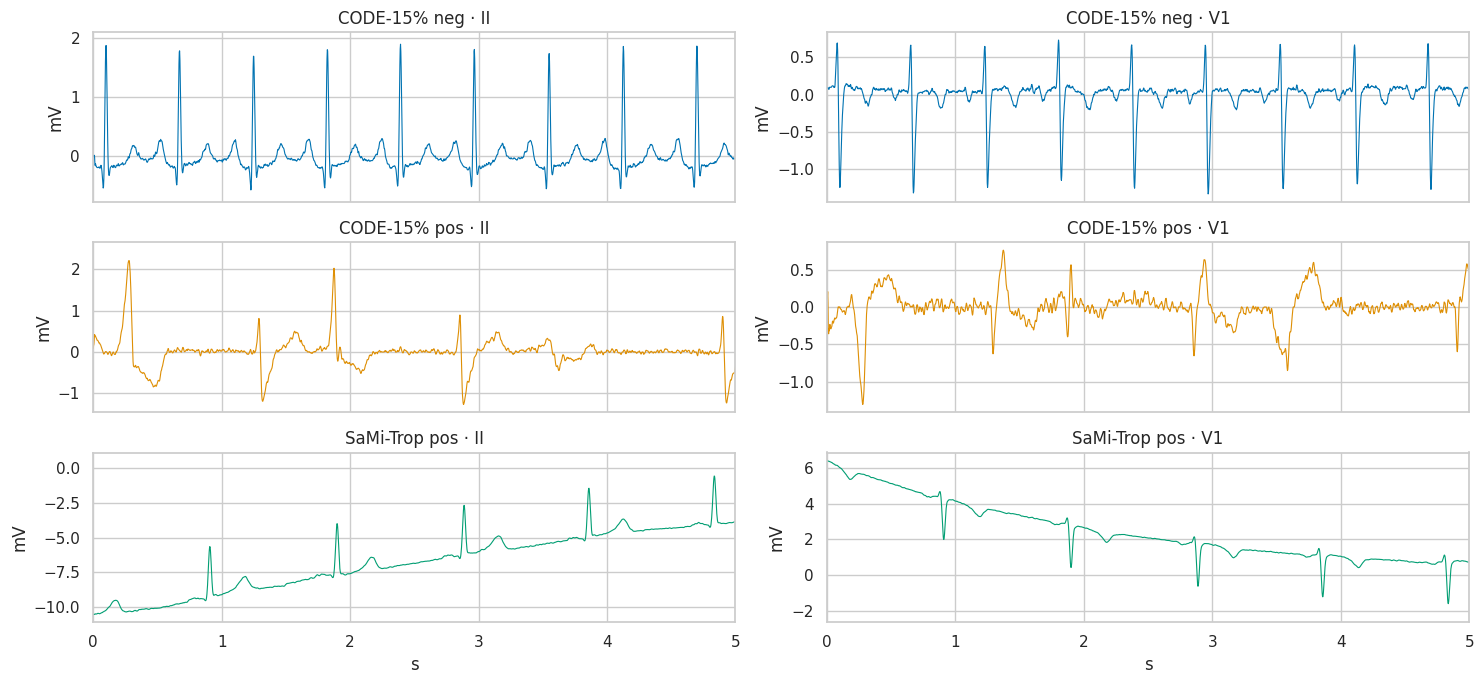

In [18]:
examples = sample.groupby("group").head(1).set_index("group").reindex(GROUPS)
fig, axes = plt.subplots(len(GROUPS), 2, figsize=(15, 7), sharex=True)
for row, group, x in zip(axes, GROUPS, sources.read_signals(examples)):
    x = ecg.trim_zero_padding(x)
    t = np.arange(len(x)) / sources.FS
    for ax, lead in zip(row, ["II", "V1"]):
        ax.plot(t, x[:, sources.LEADS.index(lead)], lw=0.8, color=PALETTE[group])
        ax.set(title=f"{group} · {lead}", xlim=(0, 5), ylabel="mV")
for ax in axes[-1]:
    ax.set_xlabel("s")
plt.tight_layout()

**Observations.** The SaMi-Trop example sits around −10 mV in lead II and drifts by several mV within 5 s, far outside physiological values. The CODE-15% positive shows wide QRS complexes at irregular intervals, the negative a regular sinus rhythm.

## 7. Spectra

Median Welch PSD per group, averaged over leads, on the trimmed signals. The panels show the full band, the baseline-wander region and the power-line region (60 Hz in Brazil). The hidden sets are sampled at 300 Hz or more, so only content below 150 Hz is available at test time.

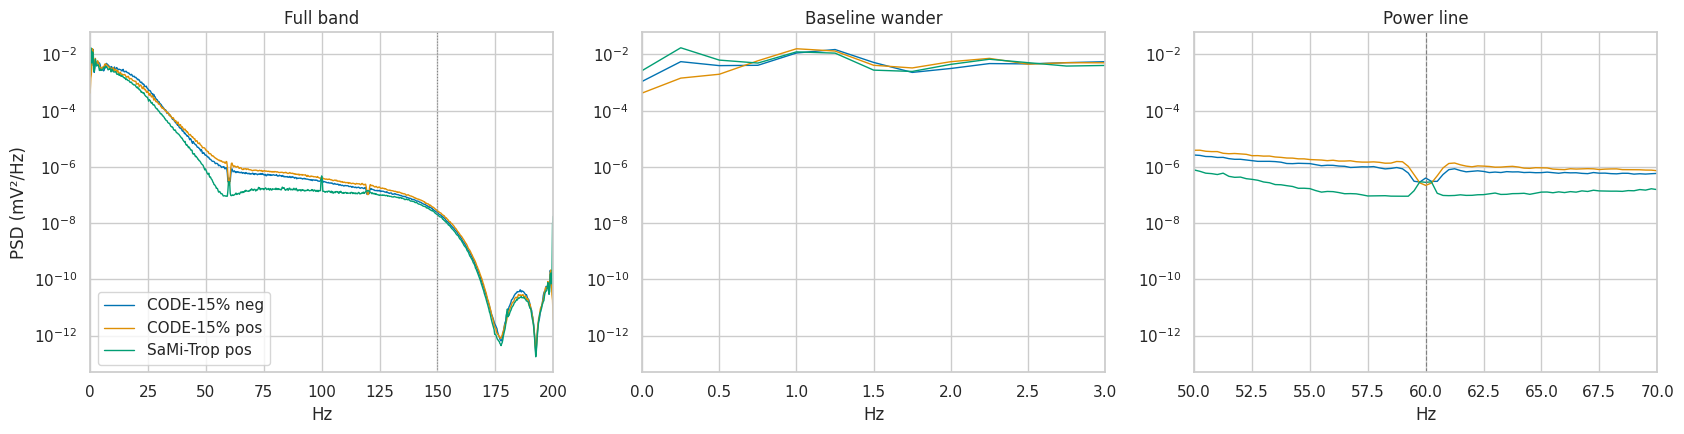

In [19]:
F = leakage.FREQS
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for group in GROUPS:
    median = np.nanmedian(spectra[(sample.group == group).to_numpy()], axis=0)
    for ax in axes:
        ax.semilogy(F, median, label=group, color=PALETTE[group], lw=1)
axes[0].set(xlim=(0, 200), title="Full band", xlabel="Hz", ylabel="PSD (mV²/Hz)")
axes[0].axvline(150, ls=":", c="grey", lw=0.8)
axes[1].set(xlim=(0, 3), title="Baseline wander", xlabel="Hz")
axes[2].set(xlim=(50, 70), title="Power line", xlabel="Hz")
axes[2].axvline(60, ls="--", c="grey", lw=0.8)
axes[0].legend()
plt.tight_layout()

In [20]:
SPECTRAL_COLS = [c for c in feats if c.startswith("power_")] + ["line_60hz"]
feats.groupby(sample.group)[SPECTRAL_COLS].median().reindex(GROUPS).T.round(4)

group,CODE-15% neg,CODE-15% pos,SaMi-Trop pos
power_0_0.5hz,0.0134,0.0044,0.0596
power_0.5_5hz,0.3216,0.3770,0.3430
power_5_15hz,0.3890,0.3937,0.3680
power_15_40hz,0.1936,0.1691,0.1163
power_40_100hz,0.0012,0.0020,0.0005
power_100_150hz,0.0001,0.0001,0.0001
power_150_200hz,0.0000,0.0000,0.0000
line_60hz,-0.1066,-0.2638,-0.0257


**Observations.**
- **Low frequencies**: below 0.5 Hz SaMi-Trop holds 6% of the power, against 1.3% for CODE-15% negatives and 0.4% for positives. Offsets and baseline wander have to be removed with a zero-phase high-pass around 0.5 Hz.
- **40–150 Hz**: SaMi-Trop has about ten times less power, the mark of a different low-pass filter at acquisition.
- **60 Hz**: CODE-15% shows a dip, likely a notch filter, and SaMi-Trop a small residual peak. Peaks at 100 and 120 Hz are visible too.
- **Above ~150 Hz** power drops by four to five orders of magnitude in every source, so the 150 Hz limit of the hidden sets costs nothing.
- Content above 40 Hz is below 0.2% of the power. A 0.5–40 Hz band-pass removes the baseline, the 60 Hz structure and the filter difference at once.

## 8. Clinical content

The CODE-15% diagnoses come from an automatic annotation system, and the hidden sets do not include them. They serve to describe the sources here and can be used as auxiliary targets later. For SaMi-Trop only `normal_ecg` is available.

In [21]:
samitrop = meta[meta.source == "SaMi-Trop"]
flags = code15[sources.CODE15_FLAGS].astype(float)

pd.DataFrame({
    "CODE-15% neg": flags[~code15.chagas].mean(),
    "CODE-15% pos": flags[code15.chagas].mean(),
    "SaMi-Trop pos": pd.Series({"normal_ecg": samitrop.normal_ecg.astype(float).mean()}),
}).reindex(sources.CODE15_FLAGS).style.format("{:.1%}", na_rep="–")

,CODE-15% neg,CODE-15% pos,SaMi-Trop pos
1dAVb,1.7%,4.0%,–
RBBB,2.3%,20.3%,–
LBBB,1.7%,3.0%,–
SB,1.6%,2.2%,–
ST,2.1%,1.7%,–
AF,2.1%,6.9%,–
normal_ecg,39.1%,14.1%,17.5%


Association of each CODE-15% diagnosis with the (self-reported) Chagas label. The share of positives with `normal_ecg` sets a ceiling for any method based on morphology alone.

In [22]:
rows = {}
for flag in sources.CODE15_FLAGS:
    has = code15[flag].astype(bool)
    a, b = (code15.chagas & has).sum(), (~code15.chagas & has).sum()
    c, d = (code15.chagas & ~has).sum(), (~code15.chagas & ~has).sum()
    rows[flag] = {"records": a + b, "prevalence if present": a / max(a + b, 1),
                  "prevalence if absent": c / max(c + d, 1), "odds ratio": a * d / max(b * c, 1)}
(pd.DataFrame(rows).T.style
   .format({"records": "{:,.0f}", "prevalence if present": "{:.2%}", "prevalence if absent": "{:.2%}",
            "odds ratio": "{:.2f}"}))

,records,prevalence if present,prevalence if absent,odds ratio
1dAVb,343,4.66%,1.97%,2.43
RBBB,525,15.62%,1.65%,11.01
LBBB,336,3.57%,1.99%,1.82
SB,317,2.84%,2.01%,1.43
ST,422,1.66%,2.03%,0.81
AF,444,6.31%,1.92%,3.43
normal_ecg,"7,694",0.74%,2.83%,0.26


**Observations.**
- RBBB is the strongest marker: 20.3% of positives against 2.3% of negatives, odds ratio 11. AF (3.4) and first-degree AV block (2.4) follow, LBBB is weak and sinus tachycardia is not associated. This is the pattern described for Chagas cardiomyopathy.
- Only 14% of CODE-15% positives have a normal ECG (17.5% in SaMi-Trop), so self-reported positives are mostly patients with ECG changes.
- Negatives come from a telehealth population where only 39% of ECGs are normal.

## 9. Duplicates between SaMi-Trop and CODE-15%

Both cohorts come from Minas Gerais and from groups linked to the same telehealth network, and the overlap is not documented. The check hashes each trimmed signal quantized to 1 µV, so only exact copies are found, and only within the downloaded CODE-15% parts.

In [23]:
def fingerprint(x):
    trimmed = ecg.trim_zero_padding(x)
    q = np.round(trimmed * 1000).astype(np.int32)
    return hashlib.blake2b(q.tobytes(), digest_size=16).hexdigest(), len(trimmed) / sources.FS

chunks = sources.iter_signals(meta, chunk_size=2000)
prints = pd.DataFrame([fingerprint(x) for _, signals in tqdm(chunks, total=ceil(len(meta) / 2000)) for x in signals],
                      index=meta.index, columns=["hash", "duration_s"])

dup = meta.join(prints)[prints.hash.map(prints.hash.value_counts()) > 1]
summary = dup.groupby("hash").agg(sources=("source", lambda s: " + ".join(sorted(set(s)))),
                                  records=("record_id", "size"), labels=("chagas", "nunique"),
                                  duration_s=("duration_s", "first"))
print(f"records sharing a signal with another record: {len(dup)} in {len(summary)} groups")
summary.sort_values("records", ascending=False).reset_index(drop=True)

  0%|          | 0/11 [00:00<?, ?it/s]

records sharing a signal with another record: 85 in 22 groups


,sources,records,labels,duration_s
0,CODE-15%,38,2,0.000
1,CODE-15%,4,1,10.240
2,CODE-15%,3,1,10.240
3,CODE-15%,3,1,10.240
4,CODE-15%,3,1,10.240
5,CODE-15%,2,1,10.240
6,CODE-15%,2,1,10.240
7,CODE-15%,2,1,10.240
8,CODE-15%,2,1,7.335
9,CODE-15%,2,1,7.335


**Observations.**
- The largest group holds 38 records that are entirely zero (duration 0), the only group with mixed labels.
- The other 21 groups are true duplicates: 47 records with different exam ids and identical signals, always with the same label.
- Preprocessing drops the empty records and keeps one record per group.
- No exact copy links SaMi-Trop to part 0 of CODE-15%, which covers 1/18 of the dataset.

## 10. Source shortcut probe

A gradient boosting classifier is trained on the acquisition features of section 6, with no access to morphology. Out-of-fold ROC AUC uses folds grouped by patient.
- **Within-class source probe**: separating CODE-15% and SaMi-Trop positives measures how visible the source is at equal label.
- **Chagas probes**: show how much of the label is predictable from acquisition alone.

The second column drops the length and padding features to check whether spectral and amplitude features leak on their own.

In [24]:
LENGTH_COLS = ["n_samples", "lead_zeros", "trail_zeros", "duration_s"]
g = sample.group
probes = {
    "source | positives (CODE-15% vs SaMi-Trop)": (g.isin(["CODE-15% pos", "SaMi-Trop pos"]), g == "SaMi-Trop pos"),
    "Chagas | pooled": (pd.Series(True, index=g.index), sample.chagas),
    "Chagas | CODE-15% only": (sample.source == "CODE-15%", sample.chagas),
}

results = {}
for name, (mask, target) in probes.items():
    row = {}
    for label, X in [("all features", feats), ("without length/padding", feats.drop(columns=LENGTH_COLS))]:
        oof = leakage.source_probe(X[mask], target[mask], sample.patient_id[mask], seed=SEED)
        row[label] = roc_auc_score(target[mask], oof)
    results[name] = row
pd.DataFrame(results).T.round(3)

,all features,without length/padding
source | positives (CODE-15% vs SaMi-Trop),0.801,0.803
Chagas | pooled,0.786,0.780
Chagas | CODE-15% only,0.742,0.733


In [25]:
mask, target = next(iter(probes.values()))
leakage.univariate_auc(feats[mask], target[mask]).rename("univariate AUC").round(3)

,univariate AUC
trail_zeros,0.763
abs_median_mv,0.743
power_40_100hz,0.733
power_0_0.5hz,0.719
duration_s,0.713
line_60hz,0.698
lead_zeros,0.675
abs_p99_mv,0.662
power_15_40hz,0.604
power_100_150hz,0.603


**Observations.**
- Acquisition features identify SaMi-Trop among positives with AUC 0.80, also without length and padding. Trailing zeros (0.76), amplitude (0.74), the 40–100 Hz band (0.73) and baseline power (0.72) each carry the source on their own.
- Within CODE-15% the same features predict the label with AUC 0.74 (0.73 without length and padding). Part of it is acquisition (duration, device), part may be physiology, since RBBB and cardiomyopathy change spectrum and amplitude. Rerunning the probe after preprocessing separates the two.

## 11. Takeaways for preprocessing

- **Band-pass 0.5–40 Hz**, zero-phase, plus per-lead mean removal: baseline, 60 Hz structure and filter differences go together.
- **Resampling to 100–125 Hz**, enough after the 40 Hz low-pass and compatible with the hidden sets.
- **Zero padding trimmed**, including the asymmetric padding of SaMi-Trop, then a **fixed window of at most 7 s** taken from the usable signal. Records shorter than the window, empty or with long flat stretches are dropped.
- **8 independent leads** (I, II, V1–V6) as input.
- **Age** capped at 90, negatives age-matched in training.
- **Evaluation** on CODE-15% held out by patient, at natural prevalence, with repeated cross-validation.
- **SaMi-Trop share** in training is a design choice, since it holds 80% of the positives.
- **Probe rerun** after preprocessing: the target is a source AUC among positives close to 0.5.